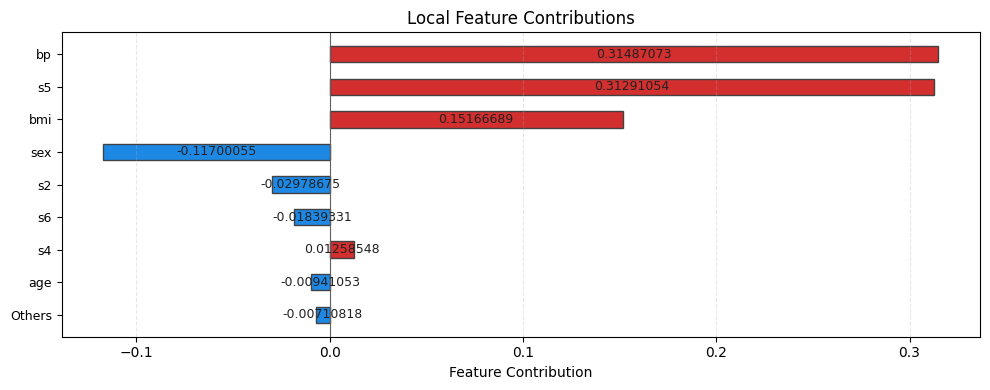

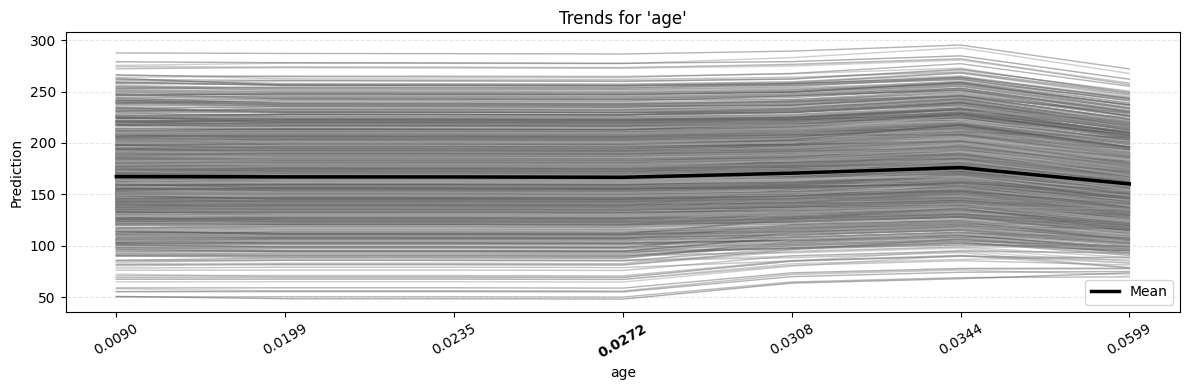

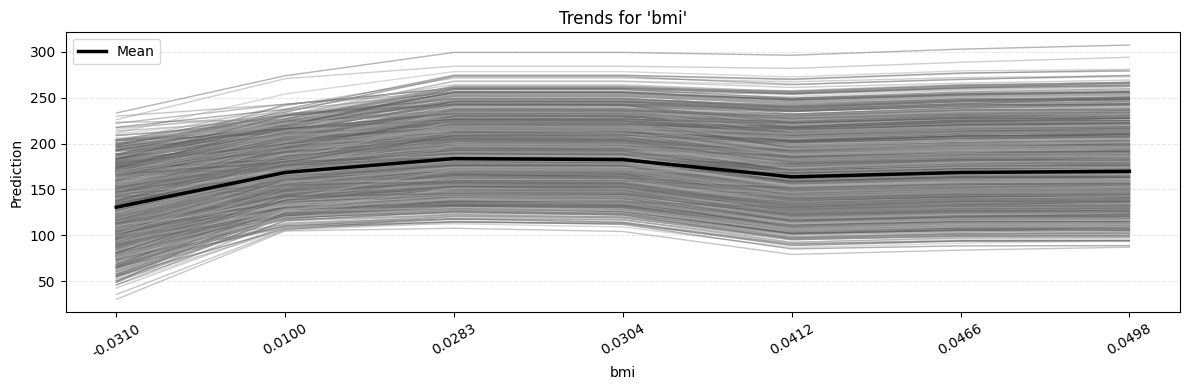

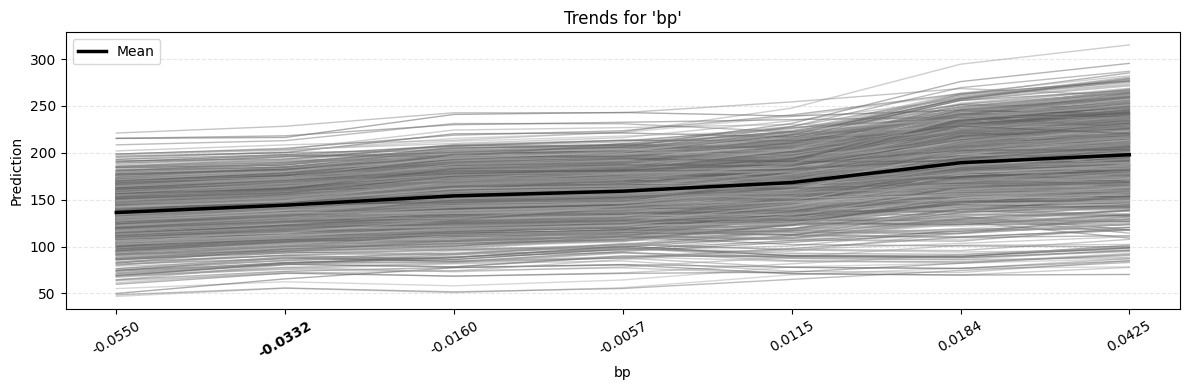

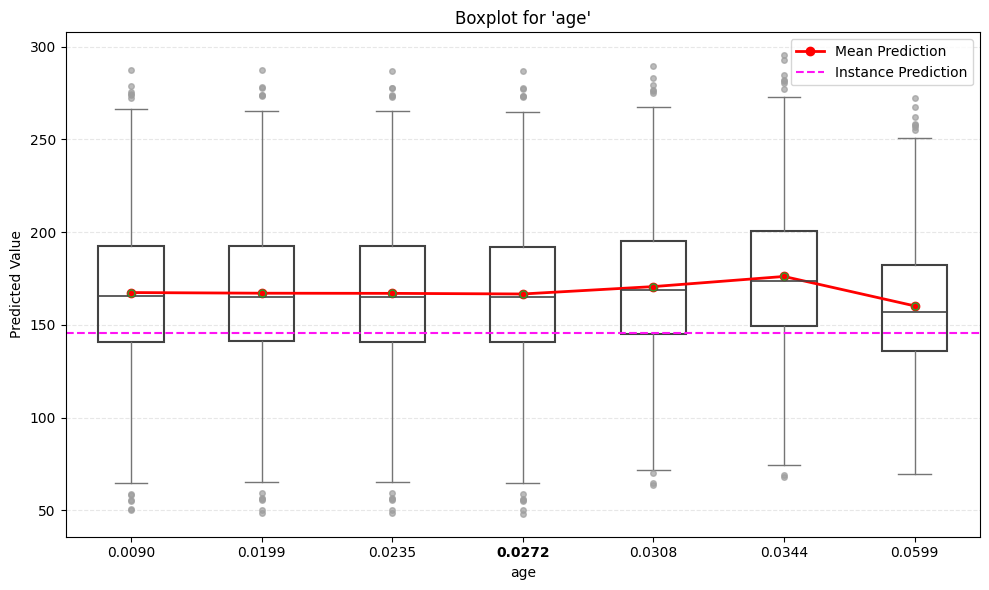

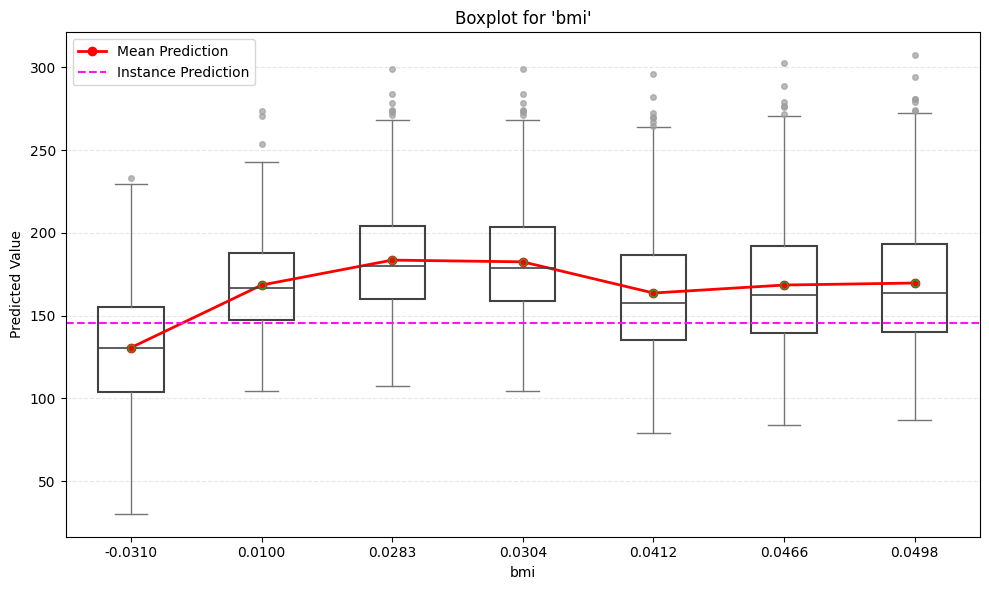

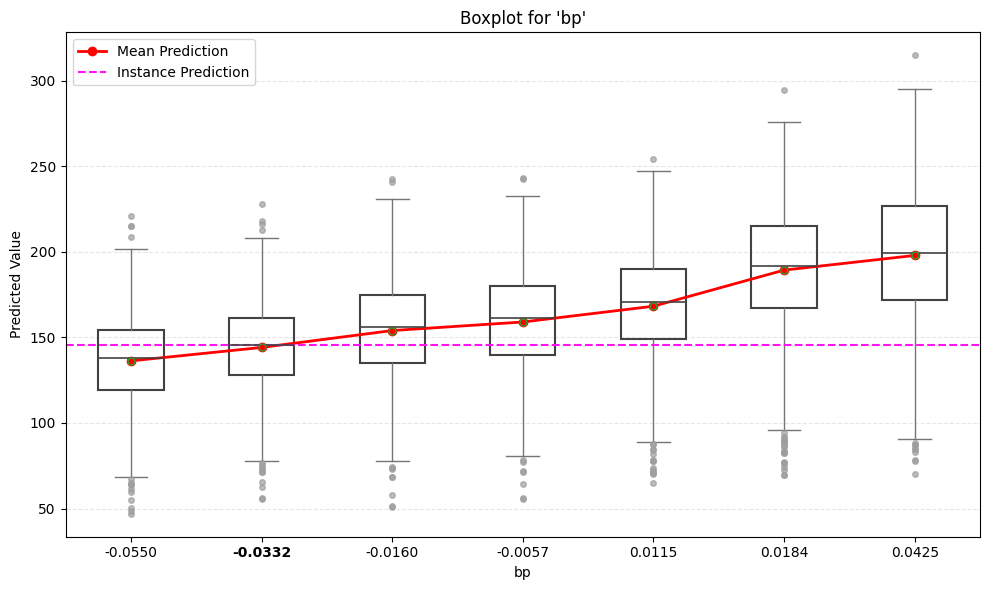

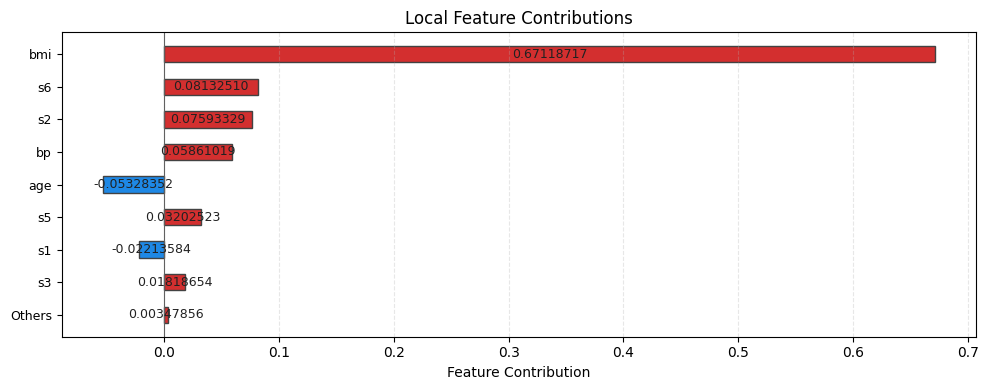

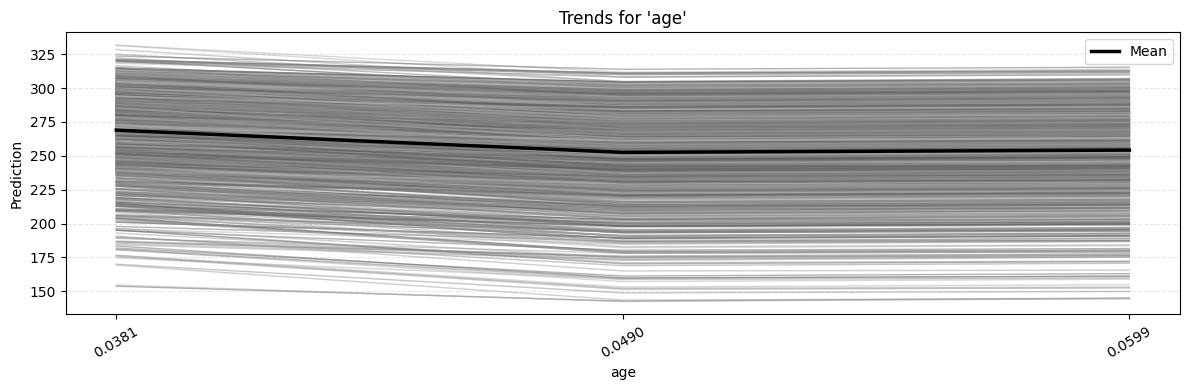

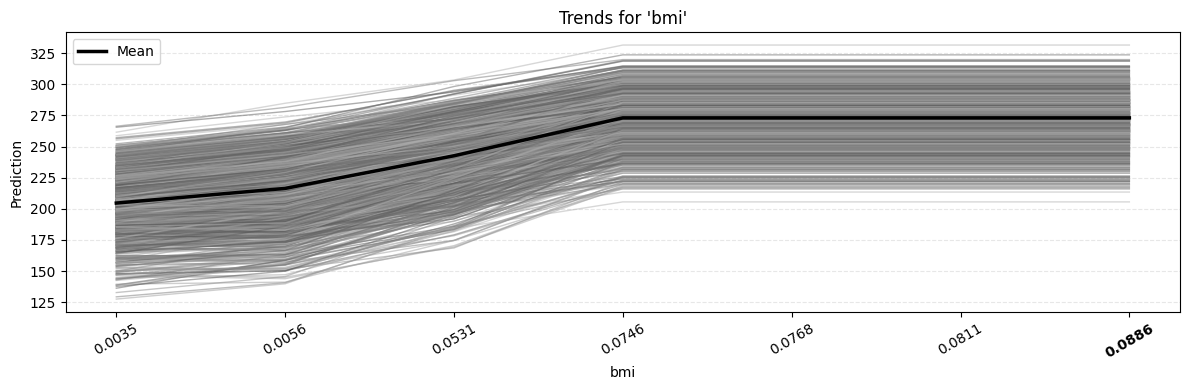

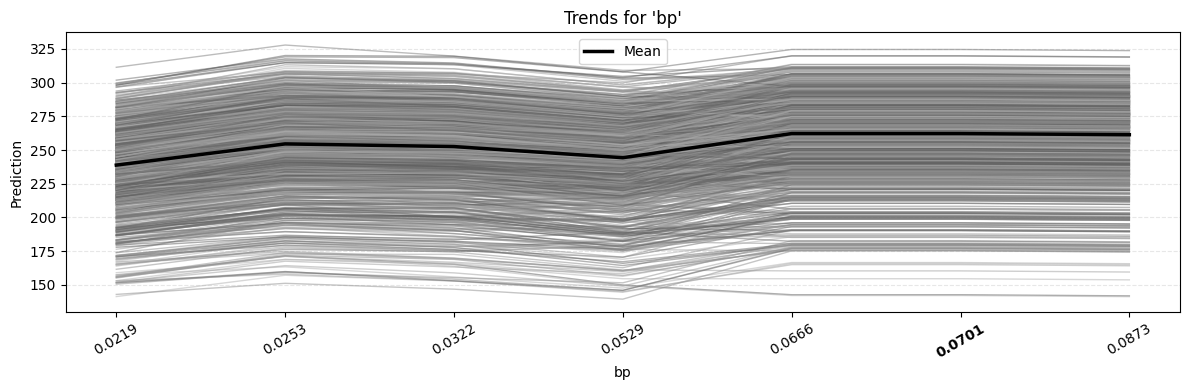

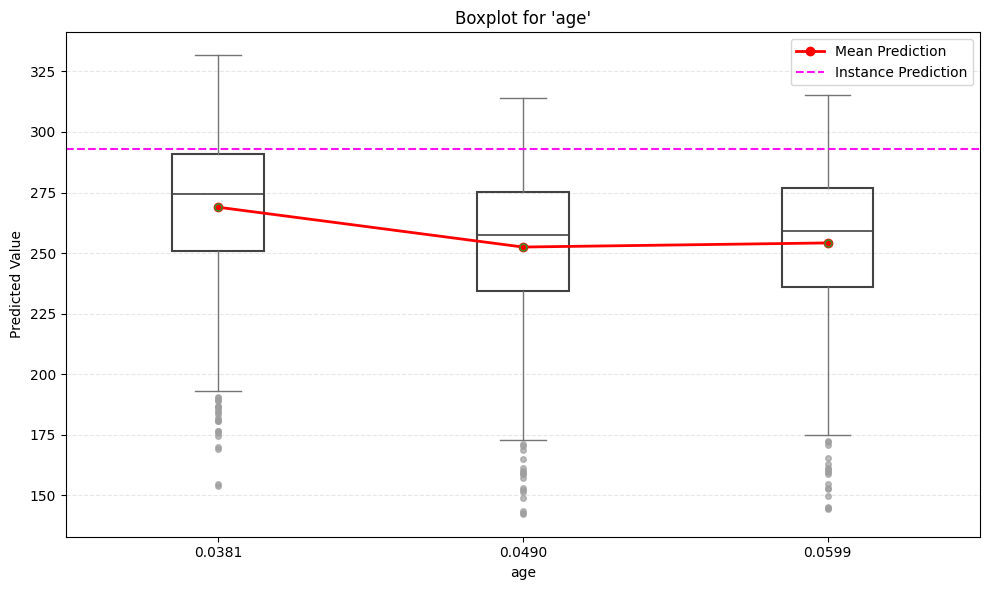

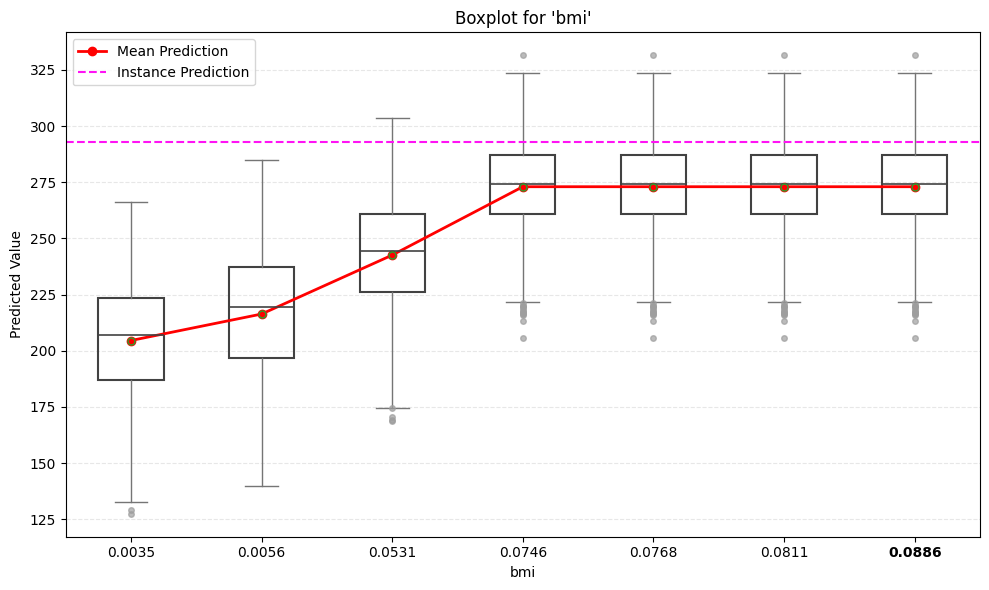

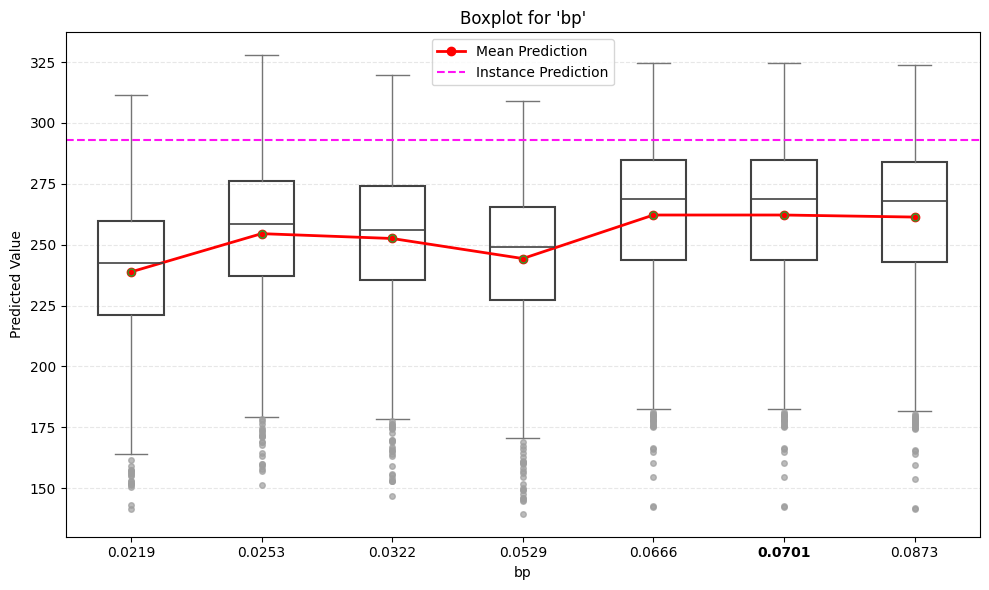

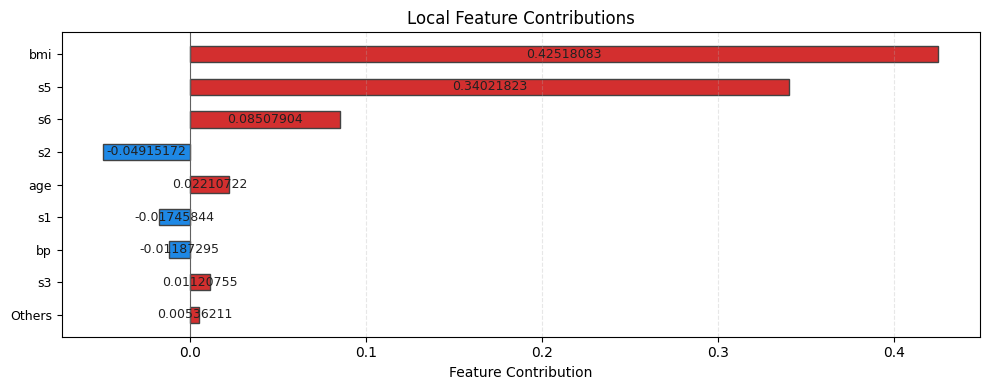

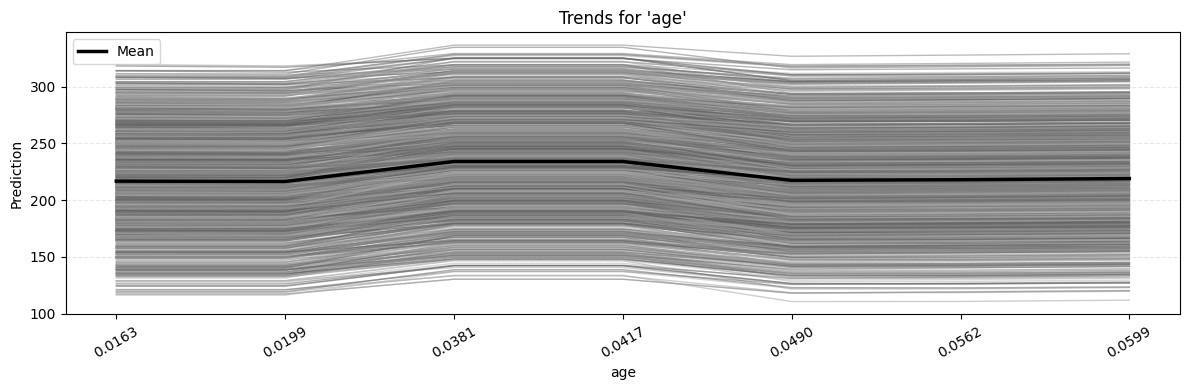

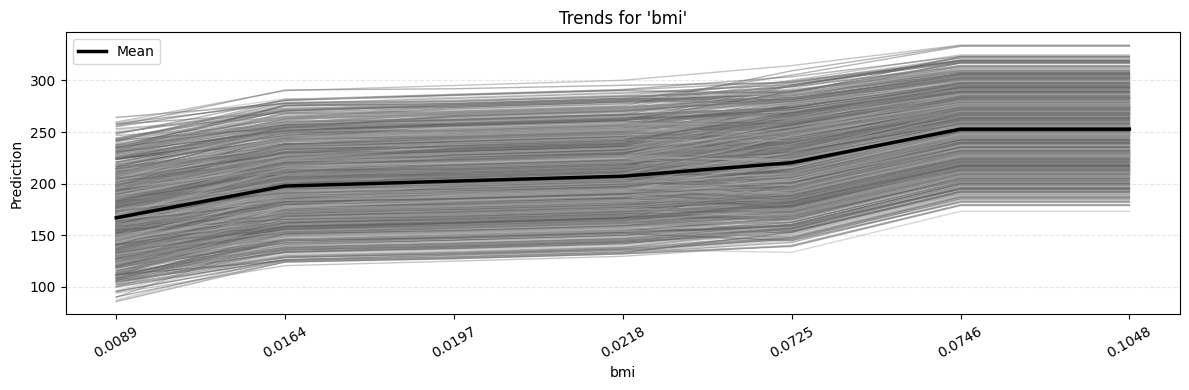

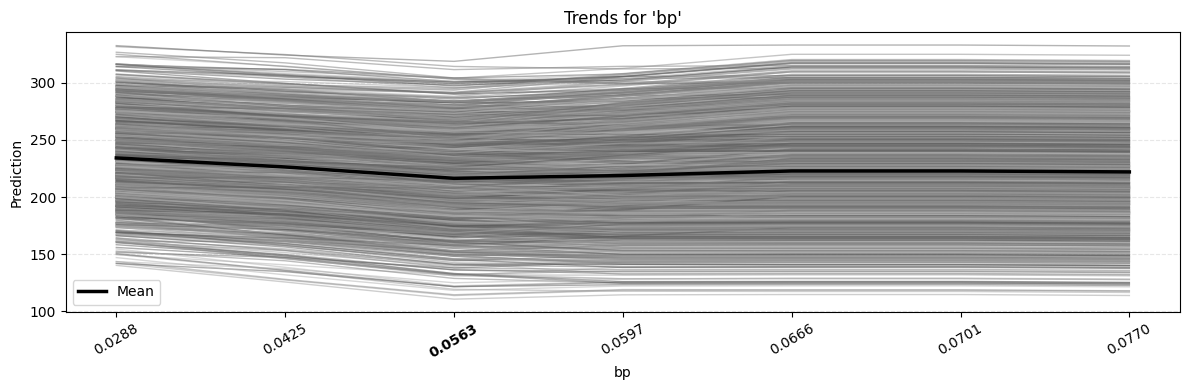

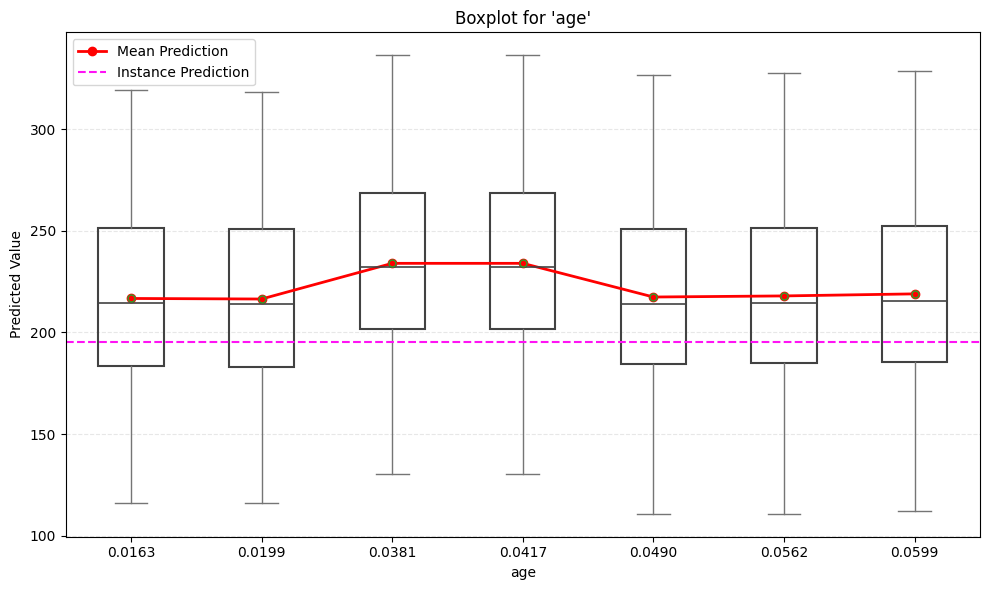

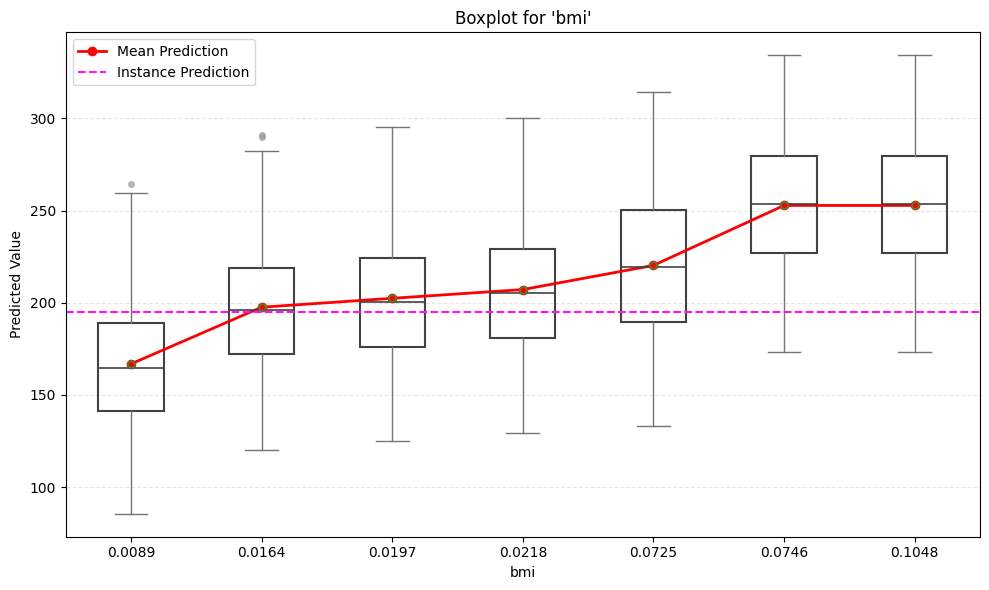

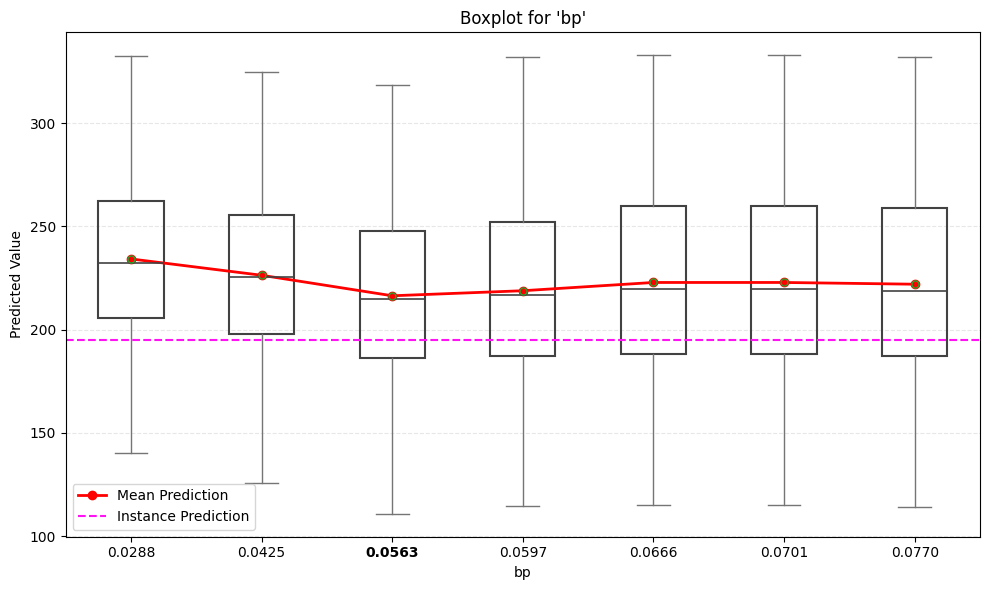

In [2]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_diabetes
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, MinMaxScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

from pathlib import Path

from luna_xai.utils import (
    ensure_directory,
)
from luna_xai.utils.normalization import arctan_normalize
from luna_xai.domains.tabular_domain_manager import TabularDomainManager
from luna_xai.data import DataInterface

from luna_xai.methods.dsa_method import DSAMethod
from luna_xai.metrics.ch_metric import CHMetric
from luna_xai.renderers.plot_renderer import PlotRenderer
from luna_xai.core.plot_exporter import MatplotlibPngExporter
from luna_xai.renderers.plot_renderer import PlotRenderer
from luna_xai.explainers.tabular_regression import TabularRegressionExplainer

# ---------------------------------------------------------------------
# ⚙️ Paths and setup of data and model
# ---------------------------------------------------------------------

# Load data
X, y = load_diabetes(return_X_y=True, as_frame=True)

# Todas as features são numéricas
NUMERIC = X.columns.tolist()

# Feature pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC),
    ]
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Prepare data
X_train_p = preprocessor.fit_transform(X_train)

model = HistGradientBoostingRegressor(
    max_depth=5,
    learning_rate=0.05,
    max_iter=500,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

model.fit(X_train_p, y_train)

# ---------------------------------------------------------------------
# ⚙️ Paths and setup of LUNA
# ---------------------------------------------------------------------
from pathlib import Path

BASE_DIR = Path.cwd()
SAVE_DIR = BASE_DIR / "saved_domain_regression"
FILES_DIR = BASE_DIR / "files"
RESULTS_DIR = BASE_DIR / "results_regression"
RANDONM_SEED = 42  # Optional

ensure_directory(RESULTS_DIR)

# ---------------------------------------------------------------------
# 📜 LUNA Domain creation
#     Perform this step only after training the model.
# ---------------------------------------------------------------------

TabularDomainManager.create_and_save(
    model=model,
    pipeline_data=preprocessor,
    pipeline_label=None,
    X_train=X_train,
    categorical_features=None,
    save_dir=SAVE_DIR,
    use_cane=False, # Only if there are categorical features in the model
    space="l2",
)

# ---------------------------------------------------------------------
# 🧱 LUNA Load persisted domain
#     Perform this step whenever you generate an explanation.
# ---------------------------------------------------------------------
domain = TabularDomainManager.load(
    save_dir=SAVE_DIR,
    model=model,
    pipeline_data=preprocessor,
    pipeline_label=None,
    categorical_features=None,
    output_dir=str(RESULTS_DIR),
 ) 

# DataInterface is already within the domain, but I will leave the explicit reference.
data_interface: DataInterface = domain.data_interface

# ---------------------------------------------------------------------
# 🧠 LUNA Build method, metric, renderer, explainer
# ---------------------------------------------------------------------
method = DSAMethod()
method.domain = domain
method.neighbor_finder = domain.get_neighbor_finder()

metric = CHMetric()

renderer = PlotRenderer(
    output_dir=str(RESULTS_DIR),
    exporter=MatplotlibPngExporter(),
    features=["age", "bmi", "bp"],
    top_k_importances=8,
    show=True,
)

explainer = TabularRegressionExplainer(
    model=model,
    domain=domain,
    method=method,
    metric=metric,
    renderer=renderer,
    output_dir=str(RESULTS_DIR),
    normalizer=arctan_normalize,
)

# ---------------------------------------------------------------------
# 🎯 LUNA Instances to explain
# ---------------------------------------------------------------------
instance_indices = [52, 17, 26]

for idx in instance_indices:

    instance = X_test.iloc[idx]

    # Full explanation (generates importances + calls renderer for local importance)
    result = explainer.explain_instance(instance, idx=str(idx), seed=RANDONM_SEED)

    # Sensitivity data available for additional charts
    sensitivity_data = result.sensitivity_data

    if sensitivity_data:

        # Original prediction of the instance
        original_prediction = float(domain.predict(instance.to_frame().T)[0])

        # 1) Line plots (ICE-like)
        renderer.plot_type = "line"
        renderer.render_from_data(
            sensitivity_data=sensitivity_data,
            plot_type="line",
            instance=instance,
            idx=str(idx),
            instance_prediction=None,  # not used in lineplot
        )

        # 2) Boxplots
        renderer.plot_type = "boxplot"
        renderer.render_from_data(
            sensitivity_data=sensitivity_data,
            plot_type="boxplot",
            instance=instance,
            idx=str(idx),
            instance_prediction=original_prediction,
        )